# Fashion-MNIST | Transfer Learning with PyTorch & ResNet-18

<div align="center">

**A reproducible computer-vision workflow — from raw pixel tables to an evaluated model**

`PYTORCH` · `TRANSFER LEARNING` · `RESNET-18` · `GPU-READY` · `MODEL EVALUATION`

</div>

---

## Project overview

This notebook trains an ImageNet-pretrained **ResNet-18** to classify the ten Fashion-MNIST clothing categories. The supplied CSV files contain flattened 28 × 28 grayscale images. We reshape each row, adapt it to the three-channel input expected by ResNet-18, and fine-tune the classifier and final residual stage.

### Workflow

1. Validate the source data and explore its visual and statistical properties.
2. Create a stratified training/validation split; reserve the supplied test set for the final evaluation.
3. Build a GPU-aware PyTorch input pipeline and transfer-learning model.
4. Train the classification head, then fine-tune the final ResNet stage.
5. Evaluate performance with class-wise metrics, confusion matrices, and error inspection.
6. Export model weights, metadata, metrics, predictions, and publication-quality figures.

### Output organization

- `images/` — saved charts and image grids (PNG).
- `artifacts/` — model checkpoint, metrics, reports, prediction tables, and metadata.

> **Reproducibility note:** all outputs are written relative to the notebook's working directory. The notebook does not print machine-specific file paths in its result cells. Run it with both CSV files available in the working directory (or a nearby parent directory).

## 1 · Environment and project setup

We begin with imports, fixed random seeds, a portable input-file resolver, and output-folder creation. The runtime automatically selects CUDA when it is available; otherwise, it runs on CPU.

In [1]:
# 1. Core libraries
import os
import json
import time
import random
import platform
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_recall_fscore_support
)

warnings.filterwarnings("ignore")
print("Core libraries imported successfully.")

Core libraries imported successfully.


In [2]:
# 2. Notebook display and plotting defaults
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", context="notebook", palette="bright")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "axes.titleweight": "bold",
    "axes.labelweight": "medium",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
})
print("Display and visualization settings are ready.")

Display and visualization settings are ready.


In [3]:
# 3. Reproducibility configuration
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Deterministic kernels improve repeatability where supported.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print(f"Random seed set to {SEED}.")

Random seed set to 42.


In [4]:
# 4. Central project configuration
TRAIN_FILE = "fashion-mnist_train.csv"
TEST_FILE = "fashion-mnist_test.csv"
IMAGE_SIZE = 96
BATCH_SIZE = 128
VALIDATION_SIZE = 0.10
HEAD_EPOCHS = 4
FINETUNE_EPOCHS = 2
HEAD_LEARNING_RATE = 1e-3
FINETUNE_LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 3
USE_PRETRAINED_WEIGHTS = True

ROOT_DIR = Path.cwd()
IMAGE_DIR = ROOT_DIR / "images"
ARTIFACT_DIR = ROOT_DIR / "artifacts"
print("Project configuration loaded.")

Project configuration loaded.


In [5]:
# 5. Create output folders and locate the supplied CSV files
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

def locate_input_file(filename):
    search_locations = [ROOT_DIR / filename, ROOT_DIR.parent / filename, Path("/mnt/data") / filename]
    for candidate in search_locations:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(
        f"Could not locate {filename}. Place it beside the notebook or in its working directory."
    )

train_csv_path = locate_input_file(TRAIN_FILE)
test_csv_path = locate_input_file(TEST_FILE)
print("Output folders are ready; both source files were found.")

Output folders are ready; both source files were found.


## 2 · Load and validate the Fashion-MNIST data

Each CSV row contains one integer label followed by 784 pixel intensities. A flattened row is reshaped to a 28 × 28 image. The source dataset is balanced, but we verify that condition rather than assume it.

In [6]:
# 6. Load the training table
train_df = pd.read_csv(train_csv_path)
print(f"Training table loaded: {train_df.shape[0]:,} rows and {train_df.shape[1]:,} columns.")

Training table loaded: 60,000 rows and 785 columns.


In [7]:
# 7. Load the official test table
test_df = pd.read_csv(test_csv_path)
print(f"Test table loaded: {test_df.shape[0]:,} rows and {test_df.shape[1]:,} columns.")

Test table loaded: 10,000 rows and 785 columns.


In [8]:
# 8. Confirm the overall dataset dimensions
print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Expected image dimensions: 28 × 28 = 784 pixel features")

Training shape: (60000, 785)
Test shape: (10000, 785)
Expected image dimensions: 28 × 28 = 784 pixel features


In [9]:
# 9. Validate the column schema
expected_columns = ["label"] + [f"pixel{i}" for i in range(1, 785)]
assert list(train_df.columns) == expected_columns, "Unexpected training CSV schema."
assert list(test_df.columns) == expected_columns, "Unexpected test CSV schema."
print("Schema validation passed: one label column and 784 ordered pixel columns.")

Schema validation passed: one label column and 784 ordered pixel columns.


In [10]:
# 10. Define the Fashion-MNIST label mapping
CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_ID = {name: idx for idx, name in enumerate(CLASS_NAMES)}
print("Class mapping:")
for idx, name in enumerate(CLASS_NAMES):
    print(f"  {idx}: {name}")

Class mapping:
  0: T-shirt/top
  1: Trouser
  2: Pullover
  3: Dress
  4: Coat
  5: Sandal
  6: Shirt
  7: Sneaker
  8: Bag
  9: Ankle boot


In [11]:
# 11. Separate labels and pixel features
pixel_columns = expected_columns[1:]
X_full = train_df[pixel_columns].to_numpy(dtype=np.uint8)
y_full = train_df["label"].to_numpy(dtype=np.int64)
X_test = test_df[pixel_columns].to_numpy(dtype=np.uint8)
y_test = test_df["label"].to_numpy(dtype=np.int64)
print(f"Training features: {X_full.shape}; labels: {y_full.shape}")
print(f"Test features: {X_test.shape}; labels: {y_test.shape}")

Training features: (60000, 784); labels: (60000,)
Test features: (10000, 784); labels: (10000,)


In [12]:
# 12. Validate label values
valid_labels = set(range(NUM_CLASSES))
assert set(np.unique(y_full)).issubset(valid_labels)
assert set(np.unique(y_test)).issubset(valid_labels)
print("Label validation passed.")

Label validation passed.


In [13]:
# 13. Check missing values
missing_train = int(train_df.isna().sum().sum())
missing_test = int(test_df.isna().sum().sum())
missing_summary = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "Missing cells": [missing_train, missing_test]
})
display(missing_summary)
assert missing_train == 0 and missing_test == 0, "Missing values require treatment before training."

,Dataset,Missing cells
0,Training,0
1,Test,0


In [14]:
# 14. Inspect duplicate records as a data-quality diagnostic
duplicate_summary = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "Duplicate rows": [int(train_df.duplicated().sum()), int(test_df.duplicated().sum())]
})
display(duplicate_summary)
print("Duplicates are reported for transparency; source rows are not silently removed.")

,Dataset,Duplicate rows
0,Training,43
1,Test,1


Duplicates are reported for transparency; source rows are not silently removed.


In [15]:
# 15. Verify pixel range and numeric type
pixel_min = int(min(X_full.min(), X_test.min()))
pixel_max = int(max(X_full.max(), X_test.max()))
print(f"Pixel range: {pixel_min} to {pixel_max}")
print("Pixel dtype:", X_full.dtype)
assert pixel_min >= 0 and pixel_max <= 255

Pixel range: 0 to 255
Pixel dtype: uint8


In [16]:
# 16. Estimate dataset memory footprint
memory_report = pd.DataFrame({
    "Array": ["Training pixels", "Test pixels", "Training labels", "Test labels"],
    "Memory (MiB)": [
        X_full.nbytes / 1024**2, X_test.nbytes / 1024**2,
        y_full.nbytes / 1024**2, y_test.nbytes / 1024**2
    ]
})
display(memory_report.round(2))

,Array,Memory (MiB)
0,Training pixels,44.86
1,Test pixels,7.48
2,Training labels,0.46
3,Test labels,0.08


In [17]:
# 17. Preview the raw tabular representation
display(train_df.head(3))

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,pixel11,pixel12,pixel13,pixel14,...,pixel770,pixel771,pixel772,pixel773,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,0,0,105,92,101,...,214,163,146,165,79,0,0,0,30,43,0,0,0,0,0


In [18]:
# 18. Convert a flattened sample into a 28 × 28 image
def to_image_array(flat_pixels):
    return np.asarray(flat_pixels, dtype=np.uint8).reshape(28, 28)

sample_image = to_image_array(X_full[0])
print("Reshaped image dimensions:", sample_image.shape)

Reshaped image dimensions: (28, 28)


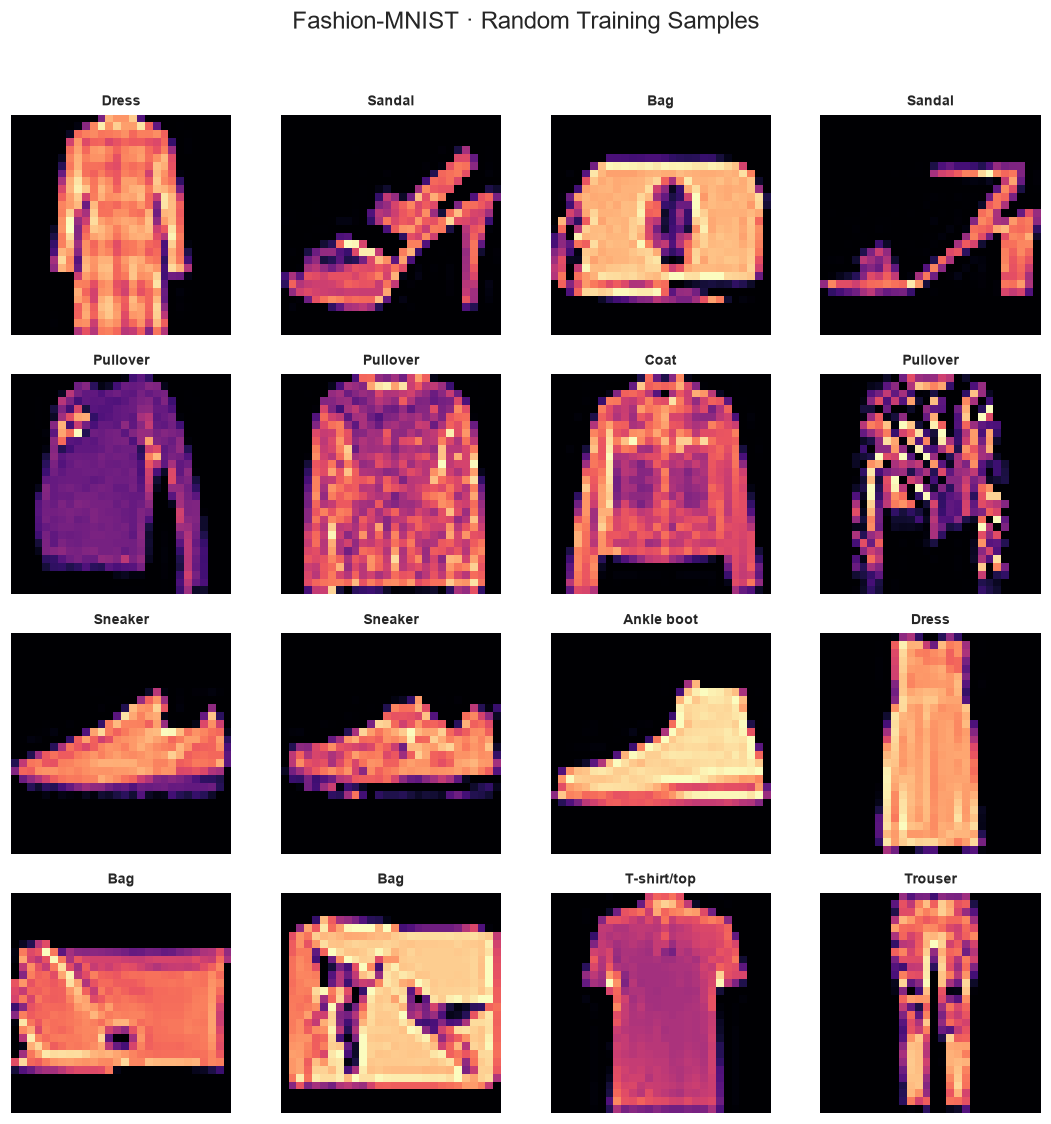

In [19]:
# 19. Visualize a random sample grid
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(X_full), size=16, replace=False)
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for ax, idx in zip(axes.flat, sample_indices):
    ax.imshow(to_image_array(X_full[idx]), cmap="magma")
    ax.set_title(CLASS_NAMES[y_full[idx]], fontsize=9)
    ax.axis("off")
fig.suptitle("Fashion-MNIST · Random Training Samples", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig(IMAGE_DIR / "01_random_training_samples.png", bbox_inches="tight")
plt.show()

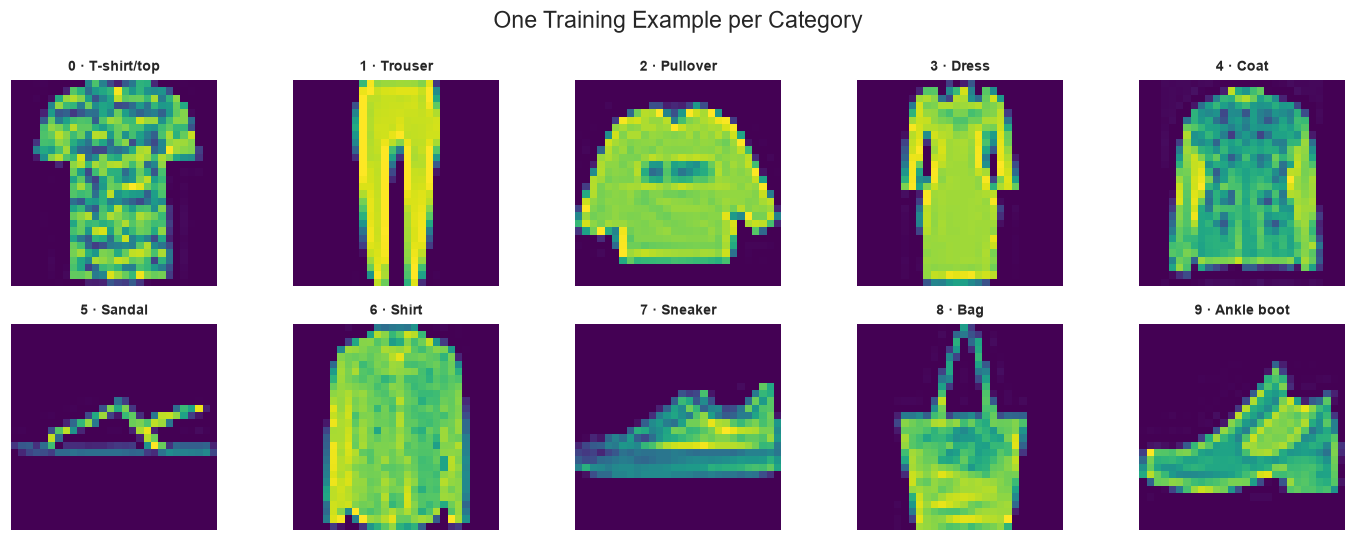

In [20]:
# 20. Show one representative example from every class
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for class_id, ax in enumerate(axes.flat):
    match = np.flatnonzero(y_full == class_id)[0]
    ax.imshow(to_image_array(X_full[match]), cmap="viridis")
    ax.set_title(f"{class_id} · {CLASS_NAMES[class_id]}", fontsize=9)
    ax.axis("off")
fig.suptitle("One Training Example per Category", fontsize=15)
plt.tight_layout()
plt.savefig(IMAGE_DIR / "02_one_example_per_class.png", bbox_inches="tight")
plt.show()

findfont: Failed to find font weight medium for Arial, now using 400.


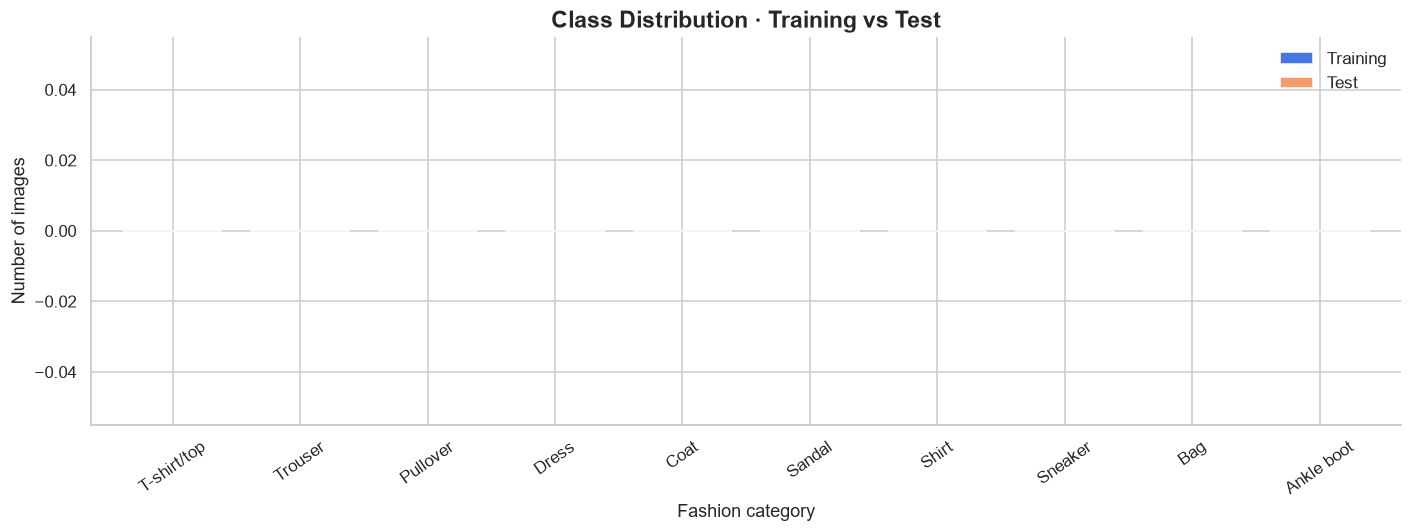

,Training,Test
T-shirt/top,NaN,NaN
Trouser,NaN,NaN
Pullover,NaN,NaN
Dress,NaN,NaN
Coat,NaN,NaN
Sandal,NaN,NaN
Shirt,NaN,NaN
Sneaker,NaN,NaN
Bag,NaN,NaN
Ankle boot,NaN,NaN


In [21]:
# 21. Plot class balance in the training and test sets
train_counts = pd.Series(y_full).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()
class_balance = pd.DataFrame({"Training": train_counts, "Test": test_counts}, index=CLASS_NAMES)
ax = class_balance.plot(kind="bar", figsize=(13, 5), width=0.78, color=["#4776E6", "#F39C6B"])
ax.set_title("Class Distribution · Training vs Test", fontsize=15)
ax.set_xlabel("Fashion category")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.savefig(IMAGE_DIR / "03_class_distribution.png", bbox_inches="tight")
plt.show()
display(class_balance)

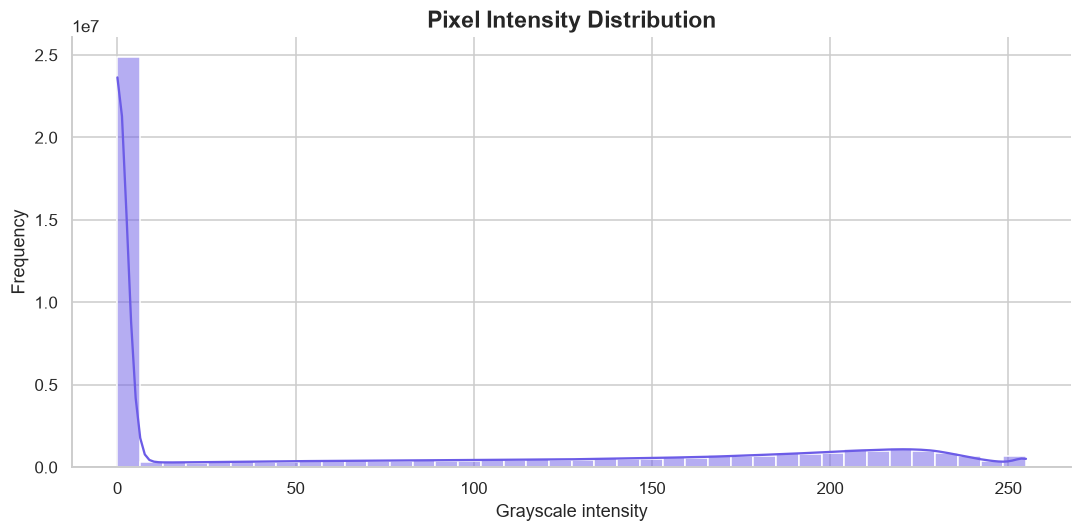

In [22]:
# 22. Explore the distribution of pixel intensities
pixel_values = X_full.reshape(-1)
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(pixel_values, bins=40, kde=True, color="#6C5CE7", ax=ax)
ax.set_title("Pixel Intensity Distribution", fontsize=15)
ax.set_xlabel("Grayscale intensity")
ax.set_ylabel("Frequency")
plt.tight_layout()
plt.savefig(IMAGE_DIR / "04_pixel_intensity_distribution.png", bbox_inches="tight")
plt.show()

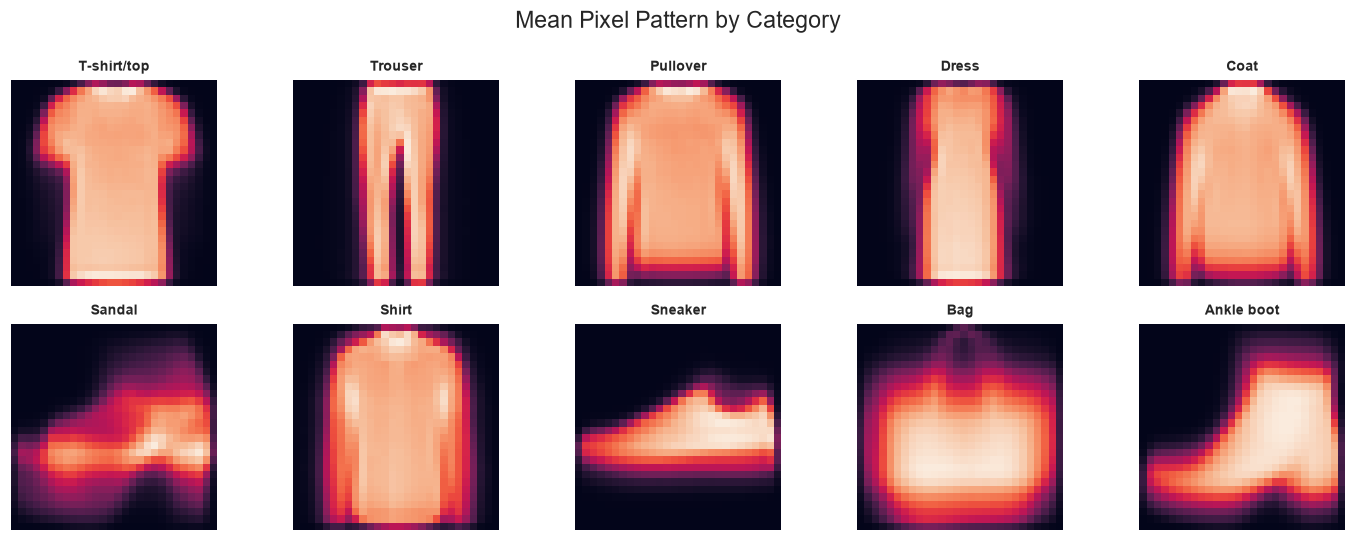

In [23]:
# 23. Compare average silhouettes by category
mean_images = np.stack([X_full[y_full == class_id].mean(axis=0).reshape(28, 28) for class_id in range(NUM_CLASSES)])
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for class_id, ax in enumerate(axes.flat):
    sns.heatmap(mean_images[class_id], cmap="rocket", cbar=False, square=True, ax=ax)
    ax.set_title(CLASS_NAMES[class_id], fontsize=9)
    ax.axis("off")
fig.suptitle("Mean Pixel Pattern by Category", fontsize=15)
plt.tight_layout()
plt.savefig(IMAGE_DIR / "05_class_mean_images.png", bbox_inches="tight")
plt.show()

In [24]:
# 24. Summarize basic pixel statistics by category
pixel_statistics = []
for class_id, class_name in enumerate(CLASS_NAMES):
    class_pixels = X_full[y_full == class_id].astype(np.float32)
    pixel_statistics.append({
        "Class": class_name,
        "Mean intensity": class_pixels.mean(),
        "Std intensity": class_pixels.std(),
        "Non-zero pixel %": 100 * np.count_nonzero(class_pixels) / class_pixels.size
    })
pixel_statistics_df = pd.DataFrame(pixel_statistics)
display(pixel_statistics_df.round(2))

,Class,Mean intensity,Std intensity,Non-zero pixel %
0,T-shirt/top,82.879997,89.199997,59.49
1,Trouser,56.750000,87.459999,34.93
2,Pullover,95.720001,91.160004,64.85
3,Dress,66.199997,90.330002,42.93
4,Coat,98.160004,95.870003,60.20
5,Sandal,34.869999,67.110001,32.10
6,Shirt,85.120003,86.690002,62.93
7,Sneaker,42.840000,75.279999,33.75
8,Bag,90.040001,93.120003,58.47
9,Ankle boot,77.010002,94.559998,48.55


## 3 · Stratified split and image preprocessing

The official test CSV remains untouched until model selection is complete. We split the supplied training set into 90% training and 10% validation with stratification, so each category is represented proportionally. ResNet-18 expects three channels; each grayscale image is therefore converted to three channels, resized, and normalized using ImageNet statistics.

In [25]:
# 25. Create a stratified training/validation split
X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=VALIDATION_SIZE,
    random_state=SEED, stratify=y_full
)
print(f"Training split: {len(X_train):,} images")
print(f"Validation split: {len(X_val):,} images")
print(f"Official test split: {len(X_test):,} images")

Training split: 54,000 images
Validation split: 6,000 images
Official test split: 10,000 images


In [26]:
# 26. Confirm split class proportions
split_counts = pd.DataFrame({
    "Training": pd.Series(y_train).value_counts(normalize=True).sort_index(),
    "Validation": pd.Series(y_val).value_counts(normalize=True).sort_index(),
    "Test": pd.Series(y_test).value_counts(normalize=True).sort_index()
}, index=CLASS_NAMES)
display((100 * split_counts).round(1).rename_axis("Class").add_suffix(" (%)"))

,Training (%),Validation (%),Test (%)
Class,,,
T-shirt/top,NaN,NaN,NaN
Trouser,NaN,NaN,NaN
Pullover,NaN,NaN,NaN
Dress,NaN,NaN,NaN
Coat,NaN,NaN,NaN
Sandal,NaN,NaN,NaN
Shirt,NaN,NaN,NaN
Sneaker,NaN,NaN,NaN
Bag,NaN,NaN,NaN


In [27]:
# 27. Define ImageNet normalization values
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
print("ImageNet normalization constants prepared.")

ImageNet normalization constants prepared.


In [28]:
# 28. Define training-time augmentation and evaluation transforms
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomAffine(degrees=8, translate=(0.06, 0.06), scale=(0.92, 1.08)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
print("Training augmentation and deterministic evaluation transforms are ready.")

Training augmentation and deterministic evaluation transforms are ready.


In [29]:
# 29. Implement a CSV-backed PyTorch Dataset
class FashionMNISTCSVDataset(Dataset):
    def __init__(self, features, labels, transform=None):
        self.features = np.asarray(features, dtype=np.uint8)
        self.labels = np.asarray(labels, dtype=np.int64)
        self.transform = transform
        if len(self.features) != len(self.labels):
            raise ValueError("Features and labels must have equal lengths.")

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = Image.fromarray(self.features[index].reshape(28, 28), mode="L")
        if self.transform is not None:
            image = self.transform(image)
        return image, int(self.labels[index])

print("Custom Dataset class defined.")

Custom Dataset class defined.


In [30]:
# 30. Build the augmented training dataset
train_dataset = FashionMNISTCSVDataset(X_train, y_train, transform=train_transform)
print(f"Training dataset contains {len(train_dataset):,} examples.")

Training dataset contains 54,000 examples.


In [31]:
# 31. Build validation and official test datasets
val_dataset = FashionMNISTCSVDataset(X_val, y_val, transform=eval_transform)
test_dataset = FashionMNISTCSVDataset(X_test, y_test, transform=eval_transform)
print("Validation and test datasets are ready.")

Validation and test datasets are ready.


In [32]:
# 32. Configure data loaders
NUM_WORKERS = 0  # Portable default for Windows, notebooks, and Colab.
PIN_MEMORY = torch.cuda.is_available()
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)
print("Data loaders created.")

Data loaders created.


In [33]:
# 33. Inspect loader sizes and batch configuration
loader_summary = pd.DataFrame({
    "Loader": ["Training", "Validation", "Test"],
    "Examples": [len(train_dataset), len(val_dataset), len(test_dataset)],
    "Batches": [len(train_loader), len(val_loader), len(test_loader)],
    "Batch size": [BATCH_SIZE] * 3
})
display(loader_summary)

,Loader,Examples,Batches,Batch size
0,Training,54000,422,128
1,Validation,6000,47,128
2,Test,10000,79,128


In [34]:
# 34. Inspect one mini-batch
batch_images, batch_labels = next(iter(train_loader))
print("Image batch shape:", tuple(batch_images.shape))
print("Label batch shape:", tuple(batch_labels.shape))
print("Image tensor dtype:", batch_images.dtype)

Image batch shape: (128, 3, 96, 96)
Label batch shape: (128,)
Image tensor dtype: torch.float32


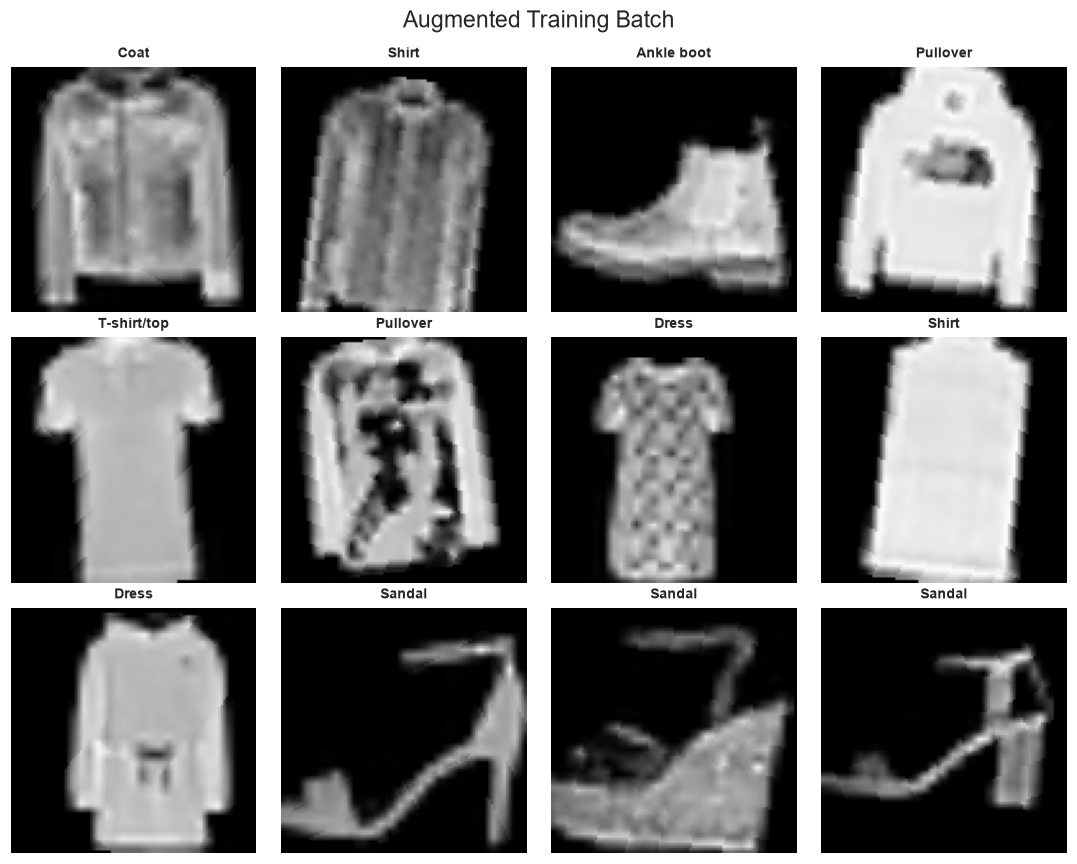

In [35]:
# 35. Visualize an augmented mini-batch
def denormalize_image(tensor_image):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    image = tensor_image.detach().cpu() * std + mean
    return image.clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for idx, ax in enumerate(axes.flat):
    ax.imshow(denormalize_image(batch_images[idx]))
    ax.set_title(CLASS_NAMES[int(batch_labels[idx])], fontsize=9)
    ax.axis("off")
fig.suptitle("Augmented Training Batch", fontsize=15)
plt.tight_layout()
plt.savefig(IMAGE_DIR / "06_augmented_batch.png", bbox_inches="tight")
plt.show()

## 4 · Build the transfer-learning model

We use ResNet-18 because it offers a strong pretrained visual backbone at a manageable computational cost. First, we freeze its feature extractor and train a new ten-class head. Next, we unfreeze `layer4` and fine-tune it at a lower learning rate. If pretrained weights cannot be downloaded in the current runtime, the notebook falls back to an uninitialized ResNet-18 and clearly reports that limitation.

In [36]:
# 36. Select the compute device and report runtime capabilities
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Selected compute device: {device.type.upper()}")
print("PyTorch version:", torch.__version__)
print("Torchvision version:", __import__("torchvision").__version__)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CUDA is unavailable; training will use CPU.")

Selected compute device: CPU
PyTorch version: 2.14.1+cu132
Torchvision version: 0.29.2+cpu
CUDA is unavailable; training will use CPU.


In [37]:
# 37. Load ResNet-18 with modern torchvision weights API
pretrained_loaded = False
try:
    selected_weights = models.ResNet18_Weights.DEFAULT if USE_PRETRAINED_WEIGHTS else None
    model = models.resnet18(weights=selected_weights)
    pretrained_loaded = selected_weights is not None
except Exception as error:
    print("Pretrained weights could not be loaded in this runtime.")
    print("Falling back to randomly initialized ResNet-18.")
    model = models.resnet18(weights=None)

print("ImageNet pretrained backbone:", "loaded" if pretrained_loaded else "not loaded")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\as178/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:09<00:00, 5.06MB/s]


ImageNet pretrained backbone: loaded


In [38]:
# 38. Freeze the pretrained feature extractor
for parameter in model.parameters():
    parameter.requires_grad = False
print("Backbone parameters frozen for the feature-extraction stage.")

Backbone parameters frozen for the feature-extraction stage.


In [39]:
# 39. Replace the original 1,000-class head with a 10-class classifier
input_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(p=0.25),
    nn.Linear(input_features, 512),
    nn.ReLU(inplace=True),
    nn.Dropout(p=0.25),
    nn.Linear(512, NUM_CLASSES)
)
print(f"Classifier replaced: {input_features:,} input features → {NUM_CLASSES} output classes.")

Classifier replaced: 512 input features → 10 output classes.


In [40]:
# 40. Move the network to the selected device
model = model.to(device)
print("Model moved to the selected compute device.")

Model moved to the selected compute device.


In [41]:
# 41. Inspect the model's final classification layer
print(model.fc)
print("Output dimension:", model.fc[-1].out_features)

Sequential(
  (0): Dropout(p=0.25, inplace=False)
  (1): Linear(in_features=512, out_features=512, bias=True)
  (2): ReLU(inplace=True)
  (3): Dropout(p=0.25, inplace=False)
  (4): Linear(in_features=512, out_features=10, bias=True)
)
Output dimension: 10


In [42]:
# 42. Count trainable and total model parameters
def count_parameters(network):
    total = sum(parameter.numel() for parameter in network.parameters())
    trainable = sum(parameter.numel() for parameter in network.parameters() if parameter.requires_grad)
    return total, trainable

total_params, trainable_params = count_parameters(model)
parameter_summary = pd.DataFrame({
    "Metric": ["Total parameters", "Trainable parameters", "Frozen parameters"],
    "Count": [total_params, trainable_params, total_params - trainable_params]
})
display(parameter_summary)
print(f"Trainable share: {100 * trainable_params / total_params:.2f}%")

,Metric,Count
0,Total parameters,11444298
1,Trainable parameters,267786
2,Frozen parameters,11176512


Trainable share: 2.34%


In [43]:
# 43. Define the multi-class classification objective
criterion = nn.CrossEntropyLoss()
print("Loss function: CrossEntropyLoss")

Loss function: CrossEntropyLoss


In [44]:
# 44. Configure the classifier-only optimizer
optimizer = torch.optim.AdamW(
    filter(lambda parameter: parameter.requires_grad, model.parameters()),
    lr=HEAD_LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
print("Optimizer configured for trainable classifier parameters.")

Optimizer configured for trainable classifier parameters.


In [45]:
# 45. Configure learning-rate scheduling and mixed precision
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=1
)
amp_enabled = device.type == "cuda"
scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)
print("Mixed precision enabled:", amp_enabled)

Mixed precision enabled: False


## 5 · Train the classification head

The training utilities calculate sample-weighted loss and accuracy across complete epochs. Validation is performed after every epoch. The best validation checkpoint is retained, and early stopping limits unnecessary training.

In [46]:
# 46. Define a reusable accuracy helper
def batch_accuracy(logits, targets):
    predictions = logits.argmax(dim=1)
    return (predictions == targets).sum().item()

print("Accuracy helper defined.")

Accuracy helper defined.


In [47]:
# 47. Implement one complete training epoch
def train_one_epoch(network, loader, loss_function, optimizer_instance, scaler_instance):
    network.train()
    running_loss, running_correct, sample_count = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer_instance.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=amp_enabled):
            logits = network(images)
            loss = loss_function(logits, labels)
        scaler_instance.scale(loss).backward()
        scaler_instance.step(optimizer_instance)
        scaler_instance.update()
        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        running_correct += batch_accuracy(logits.detach(), labels)
        sample_count += batch_size
    return running_loss / sample_count, running_correct / sample_count

print("Training epoch function defined.")

Training epoch function defined.


In [48]:
# 48. Implement evaluation without gradient tracking
def evaluate_model(network, loader, loss_function):
    network.eval()
    total_loss, total_correct, sample_count = 0.0, 0, 0
    all_labels, all_predictions, all_probabilities = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=amp_enabled):
                logits = network(images)
                loss = loss_function(logits, labels)
            probabilities = torch.softmax(logits, dim=1)
            predictions = probabilities.argmax(dim=1)
            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (predictions == labels).sum().item()
            sample_count += batch_size
            all_labels.extend(labels.cpu().numpy().tolist())
            all_predictions.extend(predictions.cpu().numpy().tolist())
            all_probabilities.append(probabilities.cpu().numpy())
    return (
        total_loss / sample_count,
        total_correct / sample_count,
        np.asarray(all_labels),
        np.asarray(all_predictions),
        np.concatenate(all_probabilities, axis=0)
    )

print("Evaluation function defined.")

Evaluation function defined.


In [49]:
# 49. Run a forward-pass shape check before training
model.eval()
with torch.no_grad():
    sanity_logits = model(batch_images[:4].to(device))
print("Sanity-check output shape:", tuple(sanity_logits.shape))
assert sanity_logits.shape == (4, NUM_CLASSES)

Sanity-check output shape: (4, 10)


In [50]:
# 50. Initialize checkpoint and training-history controls
best_checkpoint_path = ARTIFACT_DIR / "best_resnet18_fashion_mnist.pth"
best_val_accuracy = -1.0
training_history = []
print("Checkpoint and history controls initialized.")

Checkpoint and history controls initialized.


In [51]:
# 51. Define a compact epoch-recording utility
def record_epoch(stage, epoch, train_loss, train_acc, val_loss, val_acc, elapsed):
    training_history.append({
        "Stage": stage, "Epoch": int(epoch),
        "Train loss": float(train_loss), "Train accuracy": float(train_acc),
        "Validation loss": float(val_loss), "Validation accuracy": float(val_acc),
        "Epoch seconds": float(elapsed)
    })

print("Training-history utility defined.")

Training-history utility defined.


In [52]:
# 52. Train the new classification head
stale_epochs = 0
stage_start = time.time()
for epoch in range(1, HEAD_EPOCHS + 1):
    epoch_start = time.time()
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, scaler)
    val_loss, val_acc, _, _, _ = evaluate_model(model, val_loader, criterion)
    scheduler.step(val_acc)
    elapsed = time.time() - epoch_start
    record_epoch("Head training", epoch, train_loss, train_acc, val_loss, val_acc, elapsed)
    print(
        f"Head epoch {epoch:02d}/{HEAD_EPOCHS} | "
        f"train loss {train_loss:.4f} · train acc {train_acc:.3f} | "
        f"val loss {val_loss:.4f} · val acc {val_acc:.3f}"
    )
    if val_acc > best_val_accuracy:
        best_val_accuracy = val_acc
        stale_epochs = 0
        torch.save({"model_state_dict": model.state_dict(), "validation_accuracy": best_val_accuracy}, best_checkpoint_path)
    else:
        stale_epochs += 1
    if stale_epochs >= EARLY_STOPPING_PATIENCE:
        print("Early stopping reached for the head-training stage.")
        break
print(f"Head-training stage finished in {(time.time() - stage_start) / 60:.1f} minutes.")

Head epoch 01/4 | train loss 0.8430 · train acc 0.701 | val loss 0.6235 · val acc 0.783
Head epoch 02/4 | train loss 0.7143 · train acc 0.743 | val loss 0.5936 · val acc 0.789
Head epoch 03/4 | train loss 0.6835 · train acc 0.753 | val loss 0.5401 · val acc 0.808
Head epoch 04/4 | train loss 0.6623 · train acc 0.758 | val loss 0.5231 · val acc 0.815
Head-training stage finished in 23.2 minutes.


In [53]:
# 53. Review the head-training run summary
head_history = pd.DataFrame([row for row in training_history if row["Stage"] == "Head training"])
if not head_history.empty:
    display(head_history.round(4))
    print(f"Best validation accuracy so far: {best_val_accuracy:.4f}")
else:
    print("No training epochs were recorded.")

,Stage,Epoch,Train loss,Train accuracy,Validation loss,Validation accuracy,Epoch seconds
0,Head training,1,0.8430,0.7005,0.6235,0.7827,340.6201
1,Head training,2,0.7143,0.7433,0.5936,0.7888,341.6645
2,Head training,3,0.6835,0.7530,0.5401,0.8080,364.3084
3,Head training,4,0.6623,0.7576,0.5231,0.8147,347.3797


Best validation accuracy so far: 0.8147


In [54]:
# 54. Convert the full training history into a DataFrame
history_df = pd.DataFrame(training_history)
print("Recorded epochs:", len(history_df))
display(history_df.tail())

Recorded epochs: 4


,Stage,Epoch,Train loss,Train accuracy,Validation loss,Validation accuracy,Epoch seconds
0,Head training,1,0.843046,0.700537,0.623535,0.782667,340.620129
1,Head training,2,0.714293,0.743315,0.593625,0.788833,341.664460
2,Head training,3,0.683527,0.753019,0.540077,0.808000,364.308436
3,Head training,4,0.662289,0.757611,0.523121,0.814667,347.379656


In [55]:
# 55. Persist the first-stage training log
history_df.to_csv(ARTIFACT_DIR / "training_history_head.csv", index=False)
print("Head-training history saved.")

Head-training history saved.


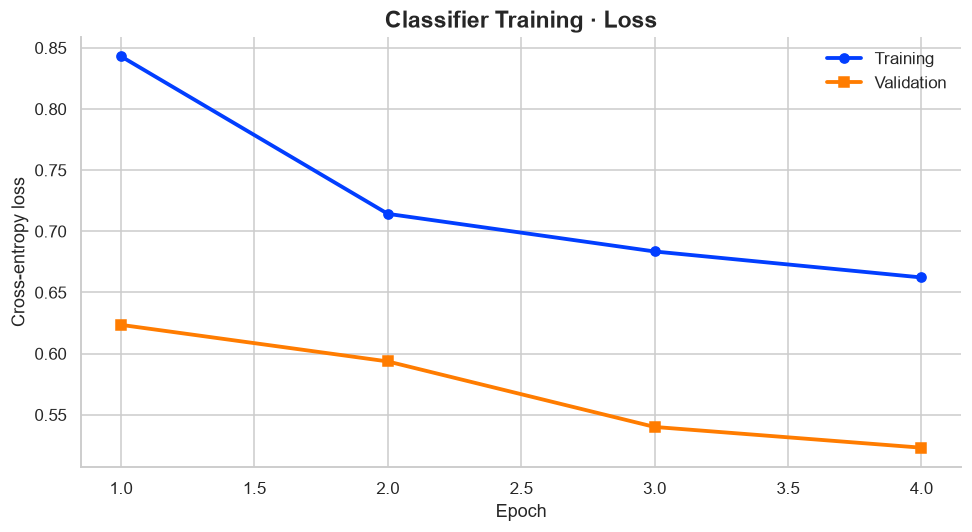

In [56]:
# 56. Plot head-training and validation loss
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(head_history["Epoch"], head_history["Train loss"], marker="o", linewidth=2.5, label="Training")
ax.plot(head_history["Epoch"], head_history["Validation loss"], marker="s", linewidth=2.5, label="Validation")
ax.set_title("Classifier Training · Loss", fontsize=15)
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.legend()
plt.tight_layout()
plt.savefig(IMAGE_DIR / "07_head_training_loss.png", bbox_inches="tight")
plt.show()

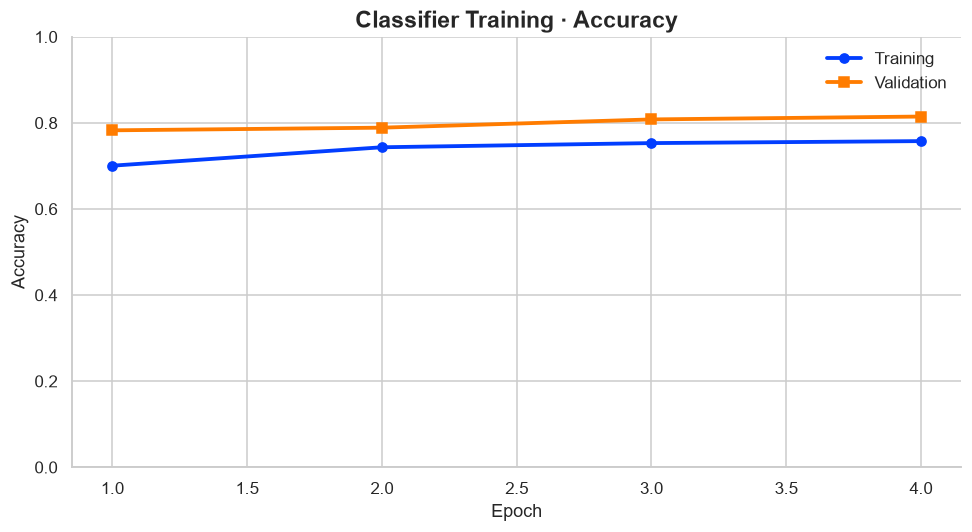

In [57]:
# 57. Plot head-training and validation accuracy
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(head_history["Epoch"], head_history["Train accuracy"], marker="o", linewidth=2.5, label="Training")
ax.plot(head_history["Epoch"], head_history["Validation accuracy"], marker="s", linewidth=2.5, label="Validation")
ax.set_title("Classifier Training · Accuracy", fontsize=15)
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.savefig(IMAGE_DIR / "08_head_training_accuracy.png", bbox_inches="tight")
plt.show()

In [58]:
# 58. Identify the best epoch from the head-training stage
best_head_row = head_history.loc[head_history["Validation accuracy"].idxmax()]
print(f"Best head epoch: {int(best_head_row['Epoch'])}")
print(f"Validation accuracy: {best_head_row['Validation accuracy']:.4f}")

Best head epoch: 4
Validation accuracy: 0.8147


In [59]:
# 59. Restore the best head-stage checkpoint before fine-tuning
checkpoint = torch.load(best_checkpoint_path, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
best_val_accuracy = float(checkpoint["validation_accuracy"])
print("Best classifier checkpoint restored.")

Best classifier checkpoint restored.


## 6 · Fine-tune the final residual stage

After the new head has learned a useful mapping, we unfreeze ResNet-18's final residual block (`layer4`). The smaller learning rate allows higher-level visual features to adapt to clothing while protecting the earlier pretrained representations.

In [60]:
# 60. Unfreeze the final residual stage
for parameter in model.layer4.parameters():
    parameter.requires_grad = True
print("Final residual stage unfrozen.")

Final residual stage unfrozen.


In [61]:
# 61. Confirm which model components are trainable
trainable_components = []
for name, parameter in model.named_parameters():
    if parameter.requires_grad:
        trainable_components.append(name.split(".")[0])
print("Trainable components:", sorted(set(trainable_components)))

Trainable components: ['fc', 'layer4']


In [62]:
# 62. Create a low-learning-rate fine-tuning optimizer
finetune_parameters = [parameter for parameter in model.parameters() if parameter.requires_grad]
optimizer = torch.optim.AdamW(
    finetune_parameters, lr=FINETUNE_LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
print(f"Fine-tuning optimizer configured for {sum(p.numel() for p in finetune_parameters):,} parameters.")

Fine-tuning optimizer configured for 8,661,514 parameters.


In [63]:
# 63. Configure the fine-tuning scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=1
)
print("Fine-tuning learning-rate scheduler configured.")

Fine-tuning learning-rate scheduler configured.


In [64]:
# 64. Initialize fine-tuning early-stopping state
stale_epochs = 0
finetune_start = time.time()
print(f"Current best validation accuracy: {best_val_accuracy:.4f}")

Current best validation accuracy: 0.8147


In [65]:
# 65. Fine-tune layer4 and the classification head
for epoch in range(1, FINETUNE_EPOCHS + 1):
    epoch_start = time.time()
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, scaler)
    val_loss, val_acc, _, _, _ = evaluate_model(model, val_loader, criterion)
    scheduler.step(val_acc)
    elapsed = time.time() - epoch_start
    record_epoch("Fine-tuning", epoch, train_loss, train_acc, val_loss, val_acc, elapsed)
    print(
        f"Fine-tune epoch {epoch:02d}/{FINETUNE_EPOCHS} | "
        f"train loss {train_loss:.4f} · train acc {train_acc:.3f} | "
        f"val loss {val_loss:.4f} · val acc {val_acc:.3f}"
    )
    if val_acc > best_val_accuracy:
        best_val_accuracy = val_acc
        stale_epochs = 0
        torch.save({"model_state_dict": model.state_dict(), "validation_accuracy": best_val_accuracy}, best_checkpoint_path)
    else:
        stale_epochs += 1
    if stale_epochs >= EARLY_STOPPING_PATIENCE:
        print("Early stopping reached for fine-tuning.")
        break
print(f"Fine-tuning stage finished in {(time.time() - finetune_start) / 60:.1f} minutes.")

Fine-tune epoch 01/2 | train loss 0.4083 · train acc 0.850 | val loss 0.2868 · val acc 0.885
Fine-tune epoch 02/2 | train loss 0.3011 · train acc 0.888 | val loss 0.2501 · val acc 0.907
Fine-tuning stage finished in 15.2 minutes.


In [66]:
# 66. Restore the strongest checkpoint across both training stages
checkpoint = torch.load(best_checkpoint_path, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
best_val_accuracy = float(checkpoint["validation_accuracy"])
model.eval()
print(f"Best validation accuracy retained: {best_val_accuracy:.4f}")

Best validation accuracy retained: 0.9070


In [67]:
# 67. Rebuild the combined training-history table
history_df = pd.DataFrame(training_history)
history_df.insert(0, "Global epoch", np.arange(1, len(history_df) + 1))
display(history_df.round(4))

,Global epoch,Stage,Epoch,Train loss,Train accuracy,Validation loss,Validation accuracy,Epoch seconds
0,1,Head training,1,0.8430,0.7005,0.6235,0.7827,340.6201
1,2,Head training,2,0.7143,0.7433,0.5936,0.7888,341.6645
2,3,Head training,3,0.6835,0.7530,0.5401,0.8080,364.3084
3,4,Head training,4,0.6623,0.7576,0.5231,0.8147,347.3797
4,5,Fine-tuning,1,0.4083,0.8499,0.2868,0.8850,460.7331
5,6,Fine-tuning,2,0.3011,0.8883,0.2501,0.9070,451.3426


In [68]:
# 68. Save the complete training history
history_df.to_csv(ARTIFACT_DIR / "training_history.csv", index=False)
print("Combined training history saved.")

Combined training history saved.


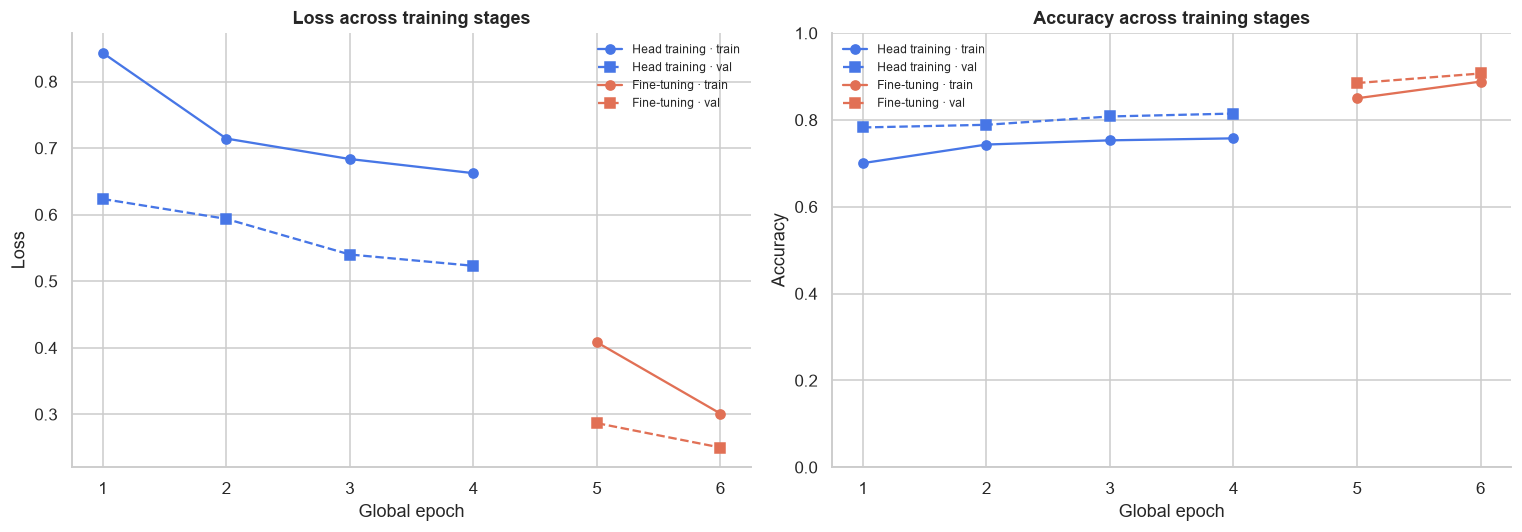

In [69]:
# 69. Plot the full training curve across both stages
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for stage_name, color in [("Head training", "#4776E6"), ("Fine-tuning", "#E17055")]:
    part = history_df[history_df["Stage"] == stage_name]
    if not part.empty:
        axes[0].plot(part["Global epoch"], part["Train loss"], marker="o", color=color, label=f"{stage_name} · train")
        axes[0].plot(part["Global epoch"], part["Validation loss"], marker="s", linestyle="--", color=color, label=f"{stage_name} · val")
        axes[1].plot(part["Global epoch"], part["Train accuracy"], marker="o", color=color, label=f"{stage_name} · train")
        axes[1].plot(part["Global epoch"], part["Validation accuracy"], marker="s", linestyle="--", color=color, label=f"{stage_name} · val")
axes[0].set_title("Loss across training stages")
axes[0].set_xlabel("Global epoch")
axes[0].set_ylabel("Loss")
axes[1].set_title("Accuracy across training stages")
axes[1].set_xlabel("Global epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(IMAGE_DIR / "09_complete_training_curves.png", bbox_inches="tight")
plt.show()

## 7 · Final evaluation

We now evaluate the selected checkpoint on the validation set and, once, on the official test set. The final test metrics are reported separately from validation performance. The notebook also produces class-wise precision, recall, F1-score, and confusion-matrix visualizations.

In [70]:
# 70. Evaluate the selected model on the validation set
val_loss_final, val_accuracy_final, y_val_true, y_val_pred, y_val_prob = evaluate_model(model, val_loader, criterion)
print(f"Validation loss: {val_loss_final:.4f}")
print(f"Validation accuracy: {val_accuracy_final:.4%}")

Validation loss: 0.2501
Validation accuracy: 90.7000%


In [71]:
# 71. Run the final official test evaluation
test_loss, test_accuracy, y_true, y_pred, y_prob = evaluate_model(model, test_loader, criterion)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4%}")

Test loss: 0.2361
Test accuracy: 91.4000%


In [72]:
# 72. Consolidate top-level evaluation metrics
test_metrics = {
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "validation_loss": float(val_loss_final),
    "validation_accuracy": float(val_accuracy_final),
    "best_validation_accuracy_during_training": float(best_val_accuracy),
    "test_examples": int(len(y_true)),
    "num_classes": int(NUM_CLASSES),
    "pretrained_weights_loaded": bool(pretrained_loaded)
}
display(pd.DataFrame([test_metrics]).T.rename(columns={0: "Value"}))

,Value
test_loss,0.236078
test_accuracy,0.914
validation_loss,0.250108
validation_accuracy,0.907
best_validation_accuracy_during_training,0.907
test_examples,10000
num_classes,10
pretrained_weights_loaded,True


In [73]:
# 73. Generate a detailed classification report
report_dict = classification_report(
    y_true, y_pred, labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES, output_dict=True, zero_division=0
)
report_df = pd.DataFrame(report_dict).T
display(report_df.round(4))

,precision,recall,f1-score,support
T-shirt/top,0.8483,0.867,0.8576,1000.000
Trouser,0.9810,0.982,0.9815,1000.000
Pullover,0.8714,0.881,0.8762,1000.000
Dress,0.8825,0.946,0.9131,1000.000
Coat,0.8742,0.869,0.8716,1000.000
Sandal,0.9808,0.973,0.9769,1000.000
Shirt,0.7944,0.707,0.7481,1000.000
Sneaker,0.9380,0.968,0.9528,1000.000
Bag,0.9861,0.993,0.9895,1000.000
Ankle boot,0.9745,0.954,0.9641,1000.000


In [74]:
# 74. Compute the raw confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
cm_df = pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES)
display(cm_df)

,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
T-shirt/top,867,4,13,31,1,1,77,0,6,0
Trouser,0,982,1,13,1,2,1,0,0,0
Pullover,14,6,881,16,42,0,40,0,1,0
Dress,13,3,3,946,16,0,19,0,0,0
Coat,0,3,50,29,869,0,44,0,5,0
Sandal,0,0,0,0,0,973,0,22,0,5
Shirt,127,3,60,36,65,0,707,0,2,0
Sneaker,0,0,0,0,0,12,0,968,0,20
Bag,1,0,3,1,0,0,2,0,993,0
Ankle boot,0,0,0,0,0,4,0,42,0,954


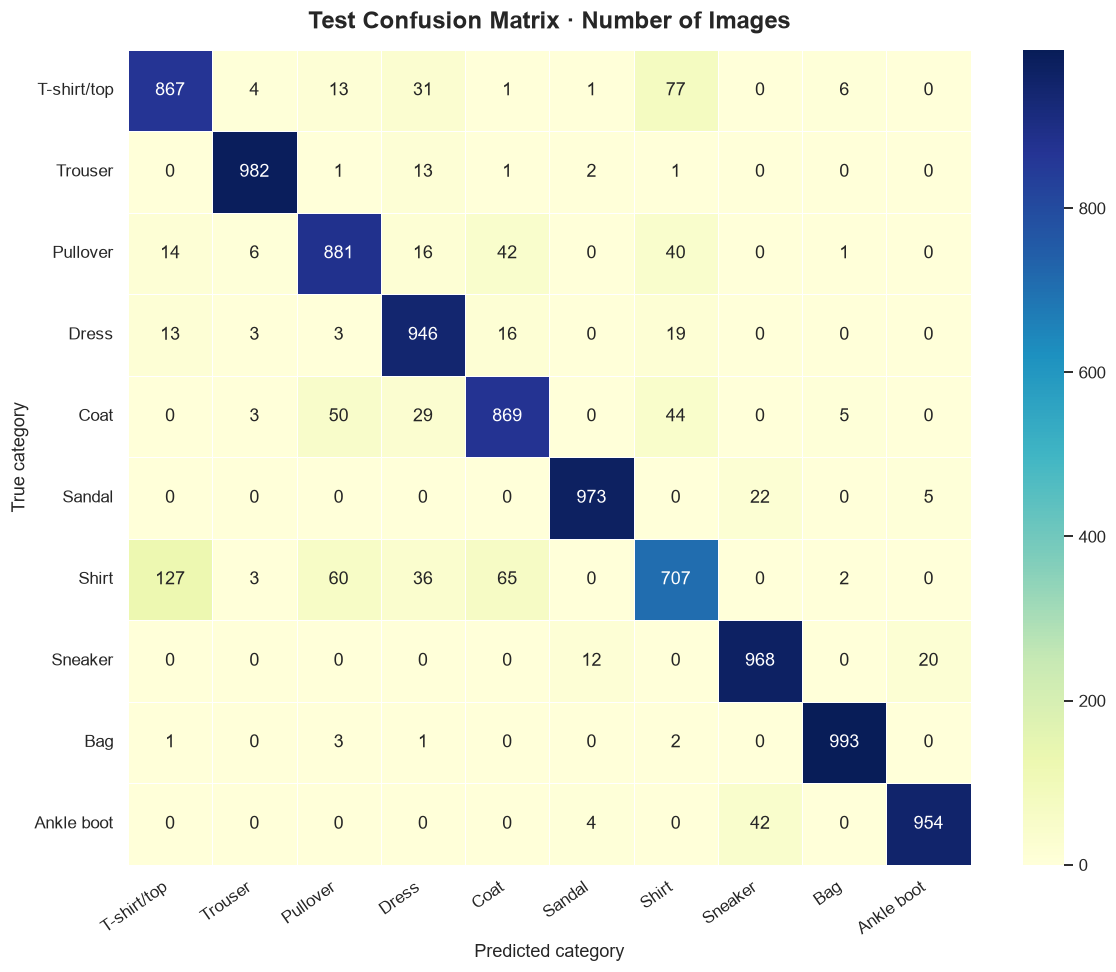

In [75]:
# 75. Visualize the raw confusion matrix
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="YlGnBu", linewidths=0.4, cbar=True, ax=ax)
ax.set_title("Test Confusion Matrix · Number of Images", fontsize=16, pad=14)
ax.set_xlabel("Predicted category")
ax.set_ylabel("True category")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(IMAGE_DIR / "10_test_confusion_matrix.png", bbox_inches="tight")
plt.show()

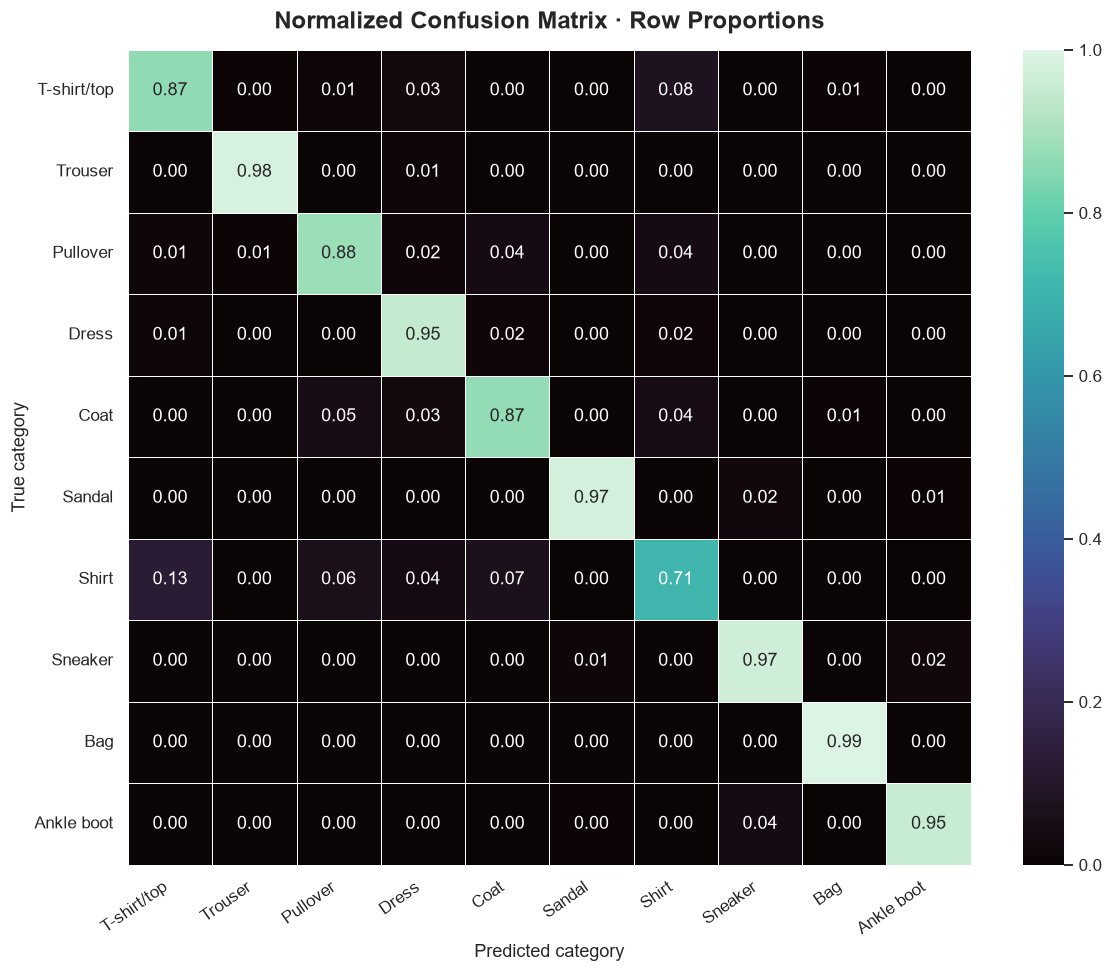

In [76]:
# 76. Visualize row-normalized confusion rates
cm_normalized = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
cm_norm_df = pd.DataFrame(cm_normalized, index=CLASS_NAMES, columns=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cm_norm_df, annot=True, fmt=".2f", cmap="mako", vmin=0, vmax=1, linewidths=0.4, ax=ax)
ax.set_title("Normalized Confusion Matrix · Row Proportions", fontsize=16, pad=14)
ax.set_xlabel("Predicted category")
ax.set_ylabel("True category")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(IMAGE_DIR / "11_normalized_confusion_matrix.png", bbox_inches="tight")
plt.show()

In [77]:
# 77. Calculate class-wise precision, recall, and F1-score
class_precision, class_recall, class_f1, class_support = precision_recall_fscore_support(
    y_true, y_pred, labels=list(range(NUM_CLASSES)), zero_division=0
)
class_metrics = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Precision": class_precision,
    "Recall": class_recall,
    "F1-score": class_f1,
    "Support": class_support,
    "Accuracy": cm.diagonal() / np.maximum(cm.sum(axis=1), 1)
})
display(class_metrics.round(4))

,Class,Precision,Recall,F1-score,Support,Accuracy
0,T-shirt/top,0.8483,0.867,0.8576,1000,0.867
1,Trouser,0.9810,0.982,0.9815,1000,0.982
2,Pullover,0.8714,0.881,0.8762,1000,0.881
3,Dress,0.8825,0.946,0.9131,1000,0.946
4,Coat,0.8742,0.869,0.8716,1000,0.869
5,Sandal,0.9808,0.973,0.9769,1000,0.973
6,Shirt,0.7944,0.707,0.7481,1000,0.707
7,Sneaker,0.9380,0.968,0.9528,1000,0.968
8,Bag,0.9861,0.993,0.9895,1000,0.993
9,Ankle boot,0.9745,0.954,0.9641,1000,0.954


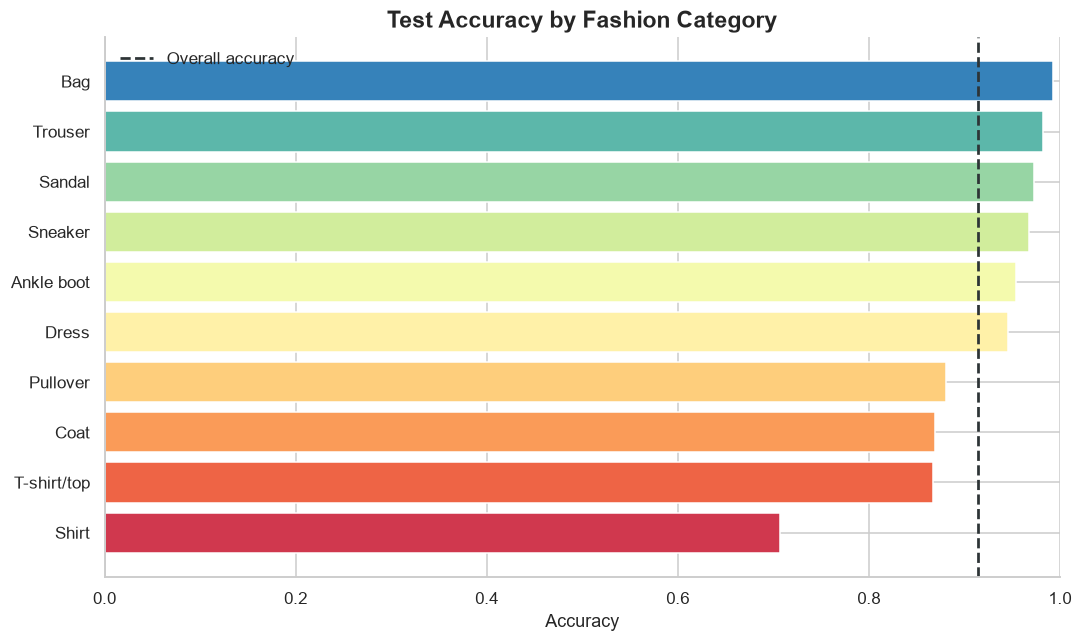

In [78]:
# 78. Compare per-class test accuracy
class_metrics_sorted = class_metrics.sort_values("Accuracy", ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
bar_colors = sns.color_palette("Spectral", n_colors=NUM_CLASSES)
ax.barh(class_metrics_sorted["Class"], class_metrics_sorted["Accuracy"], color=bar_colors)
ax.axvline(test_accuracy, color="#2D3436", linestyle="--", linewidth=1.8, label="Overall accuracy")
ax.set_xlim(0, 1)
ax.set_title("Test Accuracy by Fashion Category", fontsize=15)
ax.set_xlabel("Accuracy")
ax.set_ylabel("")
ax.legend()
plt.tight_layout()
plt.savefig(IMAGE_DIR / "12_per_class_accuracy.png", bbox_inches="tight")
plt.show()

In [79]:
# 79. Build a row-level prediction table
prediction_df = pd.DataFrame({
    "true_label": y_true,
    "true_class": [CLASS_NAMES[idx] for idx in y_true],
    "predicted_label": y_pred,
    "predicted_class": [CLASS_NAMES[idx] for idx in y_pred],
    "confidence": y_prob.max(axis=1),
    "correct": y_true == y_pred
})
for class_id, class_name in enumerate(CLASS_NAMES):
    prediction_df[f"prob_{class_id}_{class_name.lower().replace('/', '_').replace(' ', '_')}"] = y_prob[:, class_id]
display(prediction_df.head())

,true_label,true_class,predicted_label,predicted_class,confidence,correct,prob_0_t-shirt_top,prob_1_trouser,prob_2_pullover,prob_3_dress,prob_4_coat,prob_5_sandal,prob_6_shirt,prob_7_sneaker,prob_8_bag,prob_9_ankle_boot
0,0,T-shirt/top,0,T-shirt/top,0.999730,True,9.997304e-01,2.528291e-10,6.075348e-06,3.618682e-06,5.251476e-08,1.431488e-08,2.597514e-04,5.618119e-12,6.369005e-08,1.760569e-11
1,1,Trouser,1,Trouser,1.000000,True,2.887888e-12,1.000000e+00,1.881528e-11,5.381871e-09,1.891956e-12,1.798560e-15,3.256715e-12,8.122193e-16,2.080772e-14,5.496060e-14
2,2,Pullover,2,Pullover,0.971304,True,3.406496e-03,2.343443e-05,9.713036e-01,1.847811e-04,8.386669e-04,9.960473e-09,2.406678e-02,6.095746e-09,1.758263e-04,4.652207e-07
3,2,Pullover,4,Coat,0.444588,False,9.262815e-03,6.113129e-03,3.388685e-01,1.913561e-03,4.445885e-01,1.090518e-05,1.933568e-01,1.192771e-05,5.827134e-03,4.661660e-05
4,3,Dress,3,Dress,0.882865,True,3.251390e-02,4.057193e-04,5.109209e-02,8.828645e-01,2.245642e-02,9.980636e-07,1.054395e-02,5.059474e-07,1.210438e-04,9.161122e-07


In [80]:
# 80. Export the test predictions
prediction_df.to_csv(ARTIFACT_DIR / "test_predictions.csv", index=False)
print("Test prediction table saved.")

Test prediction table saved.


In [81]:
# 81. Identify the most common classification confusions
confusion_pairs = []
for true_id in range(NUM_CLASSES):
    for predicted_id in range(NUM_CLASSES):
        if true_id != predicted_id and cm[true_id, predicted_id] > 0:
            confusion_pairs.append({
                "Actual": CLASS_NAMES[true_id],
                "Predicted": CLASS_NAMES[predicted_id],
                "Count": int(cm[true_id, predicted_id])
            })
confusion_pairs_df = pd.DataFrame(confusion_pairs).sort_values("Count", ascending=False)
display(confusion_pairs_df.head(10))

,Actual,Predicted,Count
30,Shirt,T-shirt/top,127
5,T-shirt/top,Shirt,77
34,Shirt,Coat,65
32,Shirt,Pullover,60
24,Coat,Pullover,50
26,Coat,Shirt,44
43,Ankle boot,Sneaker,42
15,Pullover,Coat,42
16,Pullover,Shirt,40
33,Shirt,Dress,36


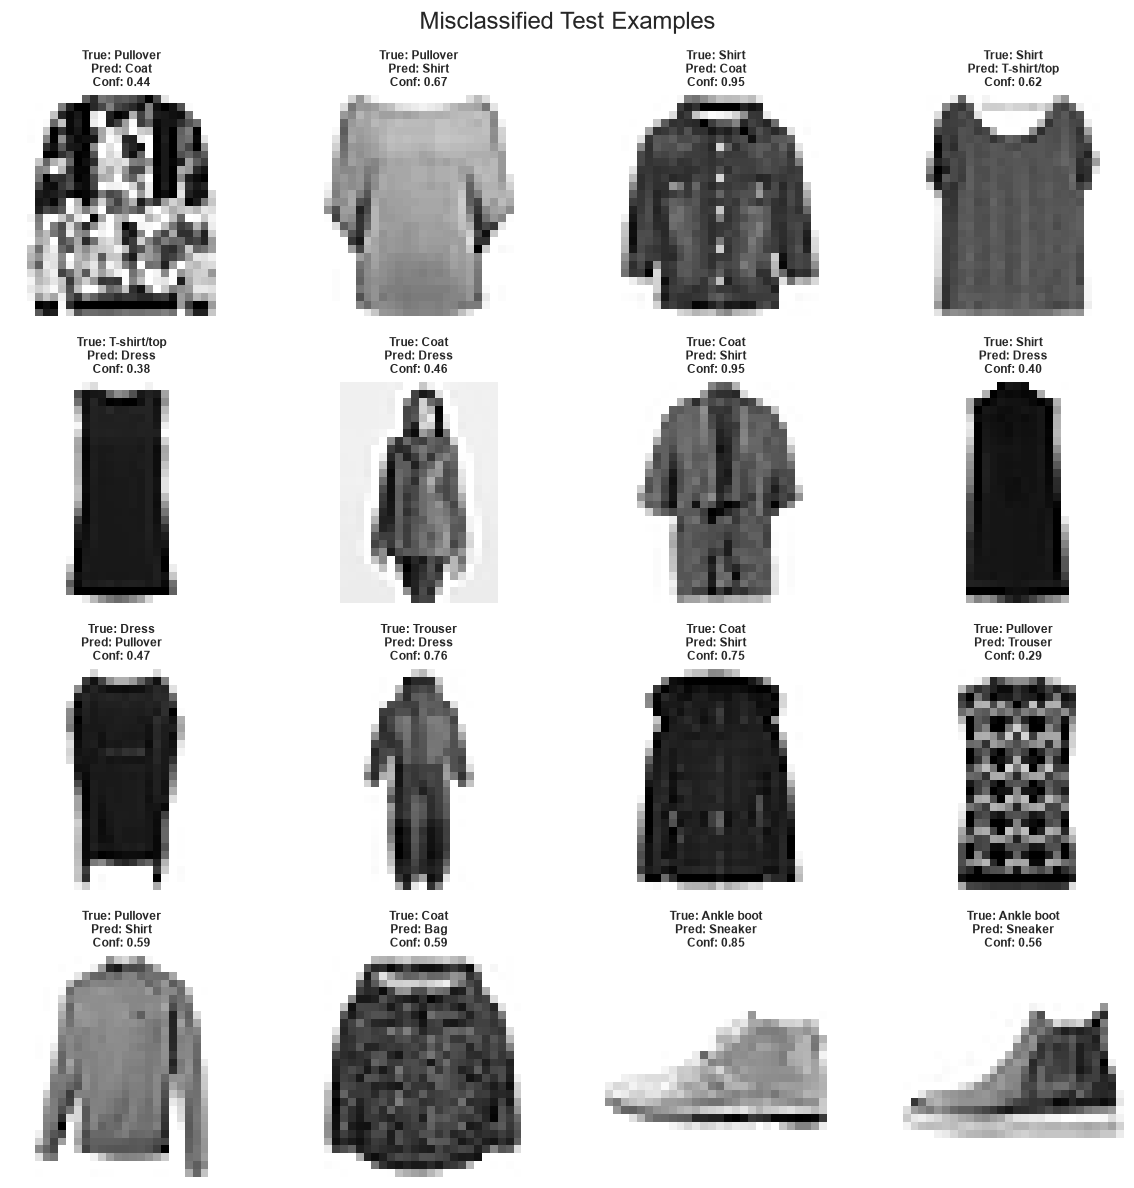

Total misclassified test examples: 860


In [82]:
# 82. Inspect representative misclassified test examples
misclassified_indices = np.flatnonzero(y_true != y_pred)
show_indices = misclassified_indices[:16]
fig, axes = plt.subplots(4, 4, figsize=(11, 11))
for ax, idx in zip(axes.flat, show_indices):
    ax.imshow(to_image_array(X_test[idx]), cmap="gray_r")
    ax.set_title(
        f"True: {CLASS_NAMES[y_true[idx]]}\nPred: {CLASS_NAMES[y_pred[idx]]}\nConf: {y_prob[idx].max():.2f}",
        fontsize=8
    )
    ax.axis("off")
for ax in axes.flat[len(show_indices):]:
    ax.axis("off")
fig.suptitle("Misclassified Test Examples", fontsize=16)
plt.tight_layout()
plt.savefig(IMAGE_DIR / "13_misclassified_examples.png", bbox_inches="tight")
plt.show()
print(f"Total misclassified test examples: {len(misclassified_indices):,}")

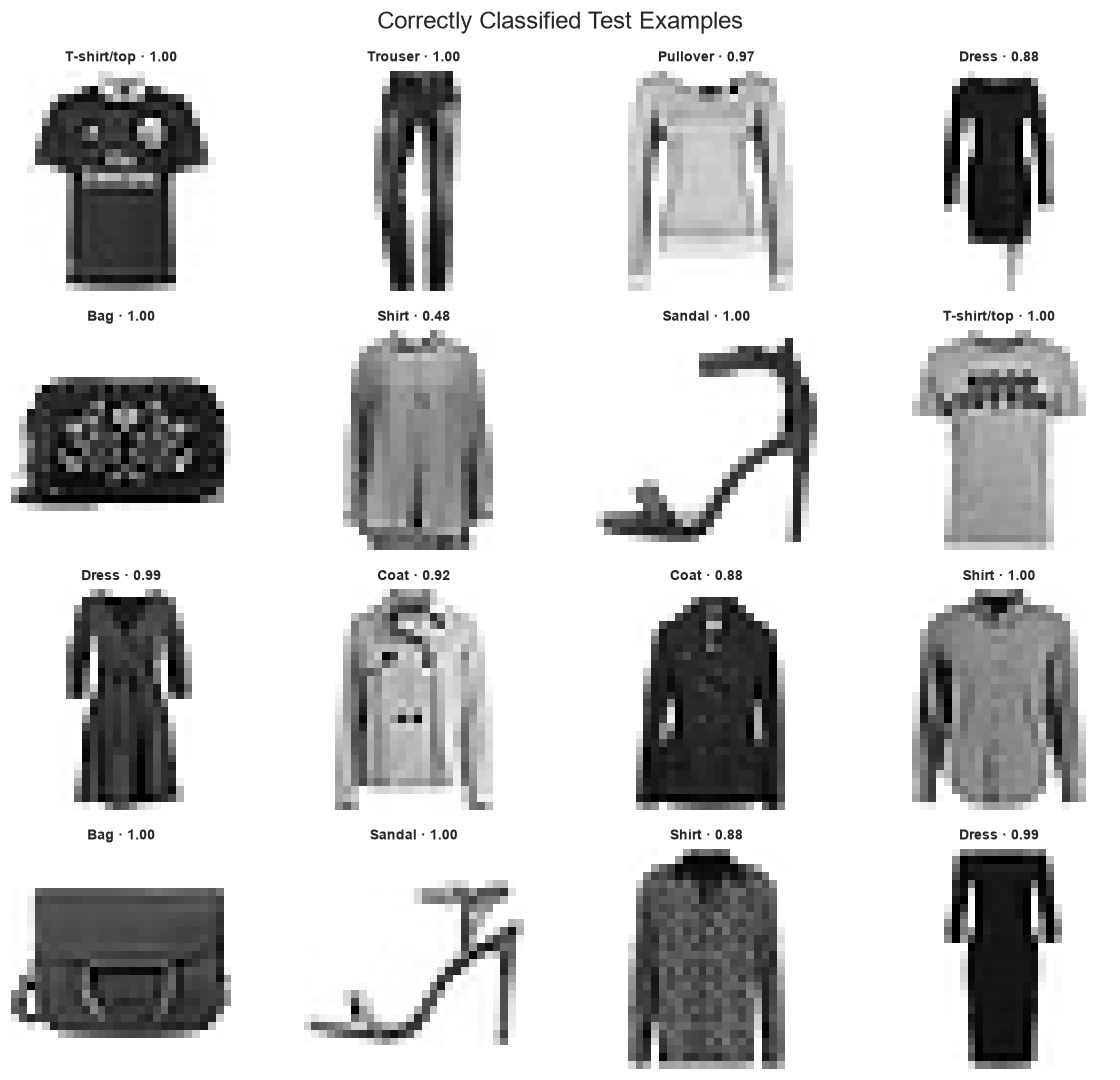

In [83]:
# 83. Inspect representative correctly classified examples
correct_indices = np.flatnonzero(y_true == y_pred)
show_correct = correct_indices[:16]
fig, axes = plt.subplots(4, 4, figsize=(11, 10))
for ax, idx in zip(axes.flat, show_correct):
    ax.imshow(to_image_array(X_test[idx]), cmap="gray_r")
    ax.set_title(f"{CLASS_NAMES[y_pred[idx]]} · {y_prob[idx].max():.2f}", fontsize=9)
    ax.axis("off")
for ax in axes.flat[len(show_correct):]:
    ax.axis("off")
fig.suptitle("Correctly Classified Test Examples", fontsize=16)
plt.tight_layout()
plt.savefig(IMAGE_DIR / "14_correct_examples.png", bbox_inches="tight")
plt.show()

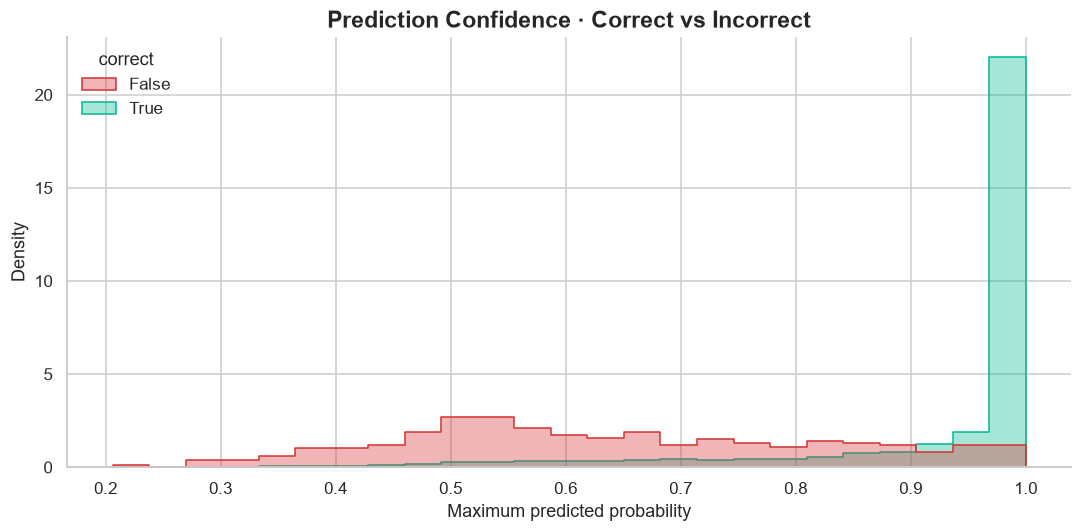

In [84]:
# 84. Examine prediction confidence for correct vs incorrect cases
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(prediction_df, x="confidence", hue="correct", bins=25, stat="density", common_norm=False,
             element="step", fill=True, alpha=0.35, palette={True: "#00B894", False: "#D63031"}, ax=ax)
ax.set_title("Prediction Confidence · Correct vs Incorrect", fontsize=15)
ax.set_xlabel("Maximum predicted probability")
ax.set_ylabel("Density")
plt.tight_layout()
plt.savefig(IMAGE_DIR / "15_prediction_confidence.png", bbox_inches="tight")
plt.show()

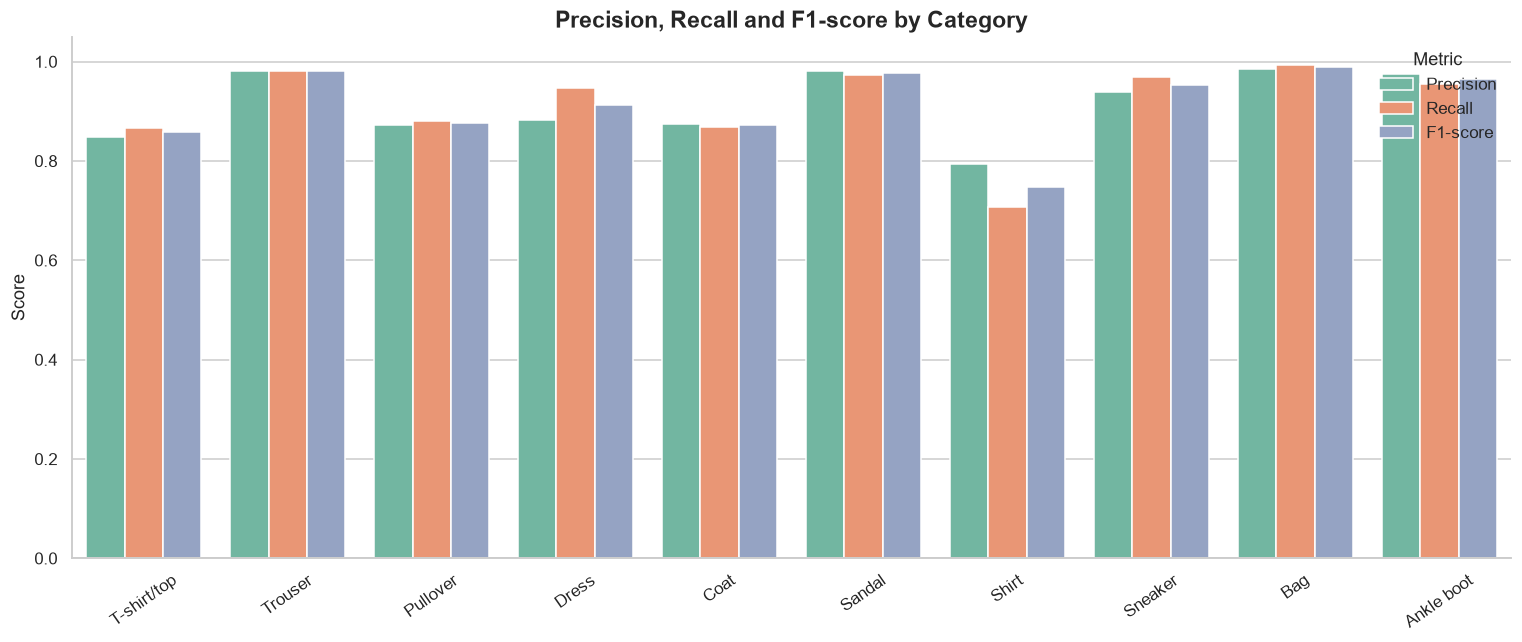

In [85]:
# 85. Compare class-wise precision, recall, and F1-score
metrics_long = class_metrics.melt(
    id_vars="Class", value_vars=["Precision", "Recall", "F1-score"],
    var_name="Metric", value_name="Score"
)
fig, ax = plt.subplots(figsize=(14, 6))
sns.barplot(data=metrics_long, x="Class", y="Score", hue="Metric", palette="Set2", ax=ax)
ax.set_title("Precision, Recall and F1-score by Category", fontsize=15)
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.savefig(IMAGE_DIR / "16_classification_metrics.png", bbox_inches="tight")
plt.show()

In [86]:
# 86. Display the highest-confidence incorrect predictions
high_confidence_errors = prediction_df.loc[~prediction_df["correct"]].nlargest(12, "confidence")
display(high_confidence_errors[["true_class", "predicted_class", "confidence"]].reset_index(names="test_row").round(4))

,test_row,true_class,predicted_class,confidence
0,7402,Sandal,Sneaker,0.9997
1,6794,Shirt,Pullover,0.9994
2,4970,Shirt,Dress,0.9957
3,7326,Shirt,Coat,0.9951
4,5927,Shirt,Dress,0.9945
5,1922,Trouser,Dress,0.9945
6,9634,Sneaker,Ankle boot,0.9915
7,2900,Coat,Dress,0.9912
8,640,Shirt,Pullover,0.9904
9,6230,Sneaker,Sandal,0.9899


## 8 · Export model and experiment artifacts

The final section saves everything needed to inspect, reproduce, and reuse the run: the best model weights, label mapping, model configuration, evaluation metrics, confusion matrix, class report, and prediction outputs. A small inference helper shows how to classify a single 28 × 28 image.

In [87]:
# 87. Save the final model checkpoint with useful metadata
final_checkpoint = {
    "model_name": "ResNet18-FashionMNIST",
    "model_state_dict": model.state_dict(),
    "class_names": CLASS_NAMES,
    "image_size": IMAGE_SIZE,
    "imagenet_mean": IMAGENET_MEAN,
    "imagenet_std": IMAGENET_STD,
    "test_accuracy": float(test_accuracy),
    "validation_accuracy": float(val_accuracy_final),
    "pretrained_weights_loaded": bool(pretrained_loaded),
    "seed": SEED
}
torch.save(final_checkpoint, ARTIFACT_DIR / "fashion_mnist_resnet18_final.pth")
print("Final model checkpoint exported.")

Final model checkpoint exported.


In [88]:
# 88. Save label mapping and model metadata
with open(ARTIFACT_DIR / "class_mapping.json", "w", encoding="utf-8") as file:
    json.dump({str(idx): name for idx, name in enumerate(CLASS_NAMES)}, file, indent=2)

model_metadata = {
    "architecture": "ResNet-18",
    "task": "10-class Fashion-MNIST image classification",
    "input_image_size": IMAGE_SIZE,
    "input_channels": 3,
    "classes": CLASS_NAMES,
    "pretrained_imagenet_weights": bool(pretrained_loaded),
    "training_strategy": "Frozen classifier head followed by layer4 fine-tuning",
    "random_seed": SEED
}
with open(ARTIFACT_DIR / "model_metadata.json", "w", encoding="utf-8") as file:
    json.dump(model_metadata, file, indent=2)
print("Class mapping and model metadata exported.")

Class mapping and model metadata exported.


In [89]:
# 89. Export the classification report and confusion matrix
report_df.to_csv(ARTIFACT_DIR / "classification_report.csv")
cm_df.to_csv(ARTIFACT_DIR / "confusion_matrix.csv")
class_metrics.to_csv(ARTIFACT_DIR / "class_metrics.csv", index=False)
print("Evaluation tables exported.")

Evaluation tables exported.


In [90]:
# 90. Export the complete evaluation summary
with open(ARTIFACT_DIR / "evaluation_metrics.json", "w", encoding="utf-8") as file:
    json.dump(test_metrics, file, indent=2)
print("Evaluation metrics exported.")

Evaluation metrics exported.


In [91]:
# 91. Export a compact experiment configuration
experiment_config = {
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "validation_fraction": VALIDATION_SIZE,
    "head_epochs_requested": HEAD_EPOCHS,
    "fine_tune_epochs_requested": FINETUNE_EPOCHS,
    "head_learning_rate": HEAD_LEARNING_RATE,
    "fine_tune_learning_rate": FINETUNE_LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "device_type": device.type,
    "torch_version": torch.__version__,
    "pretrained_weights_loaded": bool(pretrained_loaded)
}
with open(ARTIFACT_DIR / "experiment_config.json", "w", encoding="utf-8") as file:
    json.dump(experiment_config, file, indent=2)
print("Experiment configuration exported.")

Experiment configuration exported.


In [92]:
# 92. Export detailed misclassification examples
error_df = prediction_df.loc[~prediction_df["correct"]].copy()
error_df.to_csv(ARTIFACT_DIR / "misclassified_examples.csv", index=False)
print(f"Exported {len(error_df):,} misclassified examples for review.")

Exported 860 misclassified examples for review.


In [93]:
# 93. Define a reusable single-image prediction function
def predict_fashion_image(flat_pixels, trained_model=model):
    """Predict one flattened 784-pixel Fashion-MNIST example."""
    image = Image.fromarray(np.asarray(flat_pixels, dtype=np.uint8).reshape(28, 28), mode="L")
    input_tensor = eval_transform(image).unsqueeze(0).to(device)
    trained_model.eval()
    with torch.no_grad():
        logits = trained_model(input_tensor)
        probabilities = torch.softmax(logits, dim=1).squeeze(0).cpu().numpy()
    predicted_id = int(probabilities.argmax())
    return {
        "predicted_id": predicted_id,
        "predicted_class": CLASS_NAMES[predicted_id],
        "confidence": float(probabilities[predicted_id]),
        "probabilities": probabilities
    }

print("Single-image inference function defined.")

Single-image inference function defined.


In [94]:
# 94. Run one inference example from the test set
example_result = predict_fashion_image(X_test[0])
print("Predicted class:", example_result["predicted_class"])
print("True class:", CLASS_NAMES[int(y_test[0])])
print(f"Confidence: {example_result['confidence']:.2%}")

Predicted class: T-shirt/top
True class: T-shirt/top
Confidence: 99.97%


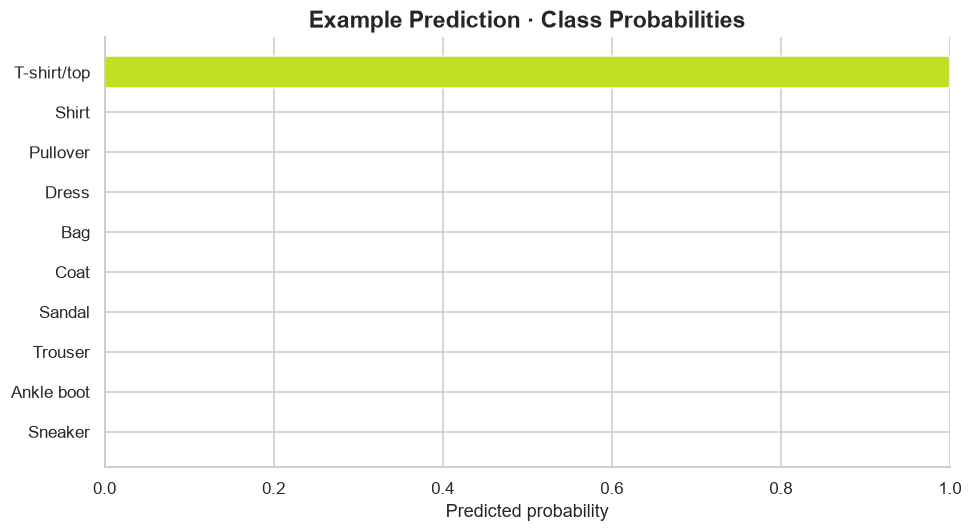

In [95]:
# 95. Visualize class probabilities for the inference example
probability_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Probability": example_result["probabilities"]
}).sort_values("Probability", ascending=True)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(probability_df["Class"], probability_df["Probability"], color=sns.color_palette("viridis", NUM_CLASSES))
ax.set_xlim(0, 1)
ax.set_title("Example Prediction · Class Probabilities", fontsize=15)
ax.set_xlabel("Predicted probability")
plt.tight_layout()
plt.savefig(IMAGE_DIR / "17_single_example_probabilities.png", bbox_inches="tight")
plt.show()

In [96]:
# 96. Save the class-probability table for the example
probability_df.to_csv(ARTIFACT_DIR / "example_prediction_probabilities.csv", index=False)
print("Example prediction probabilities exported.")

Example prediction probabilities exported.


In [97]:
# 97. Create a concise experiment summary table
experiment_summary = pd.DataFrame({
    "Item": [
        "Architecture", "Pretrained weights", "Training examples", "Validation examples",
        "Official test examples", "Best validation accuracy", "Test accuracy", "Test loss"
    ],
    "Result": [
        "ResNet-18", "Loaded" if pretrained_loaded else "Unavailable — random initialization",
        f"{len(train_dataset):,}", f"{len(val_dataset):,}", f"{len(test_dataset):,}",
        f"{best_val_accuracy:.2%}", f"{test_accuracy:.2%}", f"{test_loss:.4f}"
    ]
})
display(experiment_summary)

,Item,Result
0,Architecture,ResNet-18
1,Pretrained weights,Loaded
2,Training examples,"54,000"
3,Validation examples,"6,000"
4,Official test examples,"10,000"
5,Best validation accuracy,90.70%
6,Test accuracy,91.40%
7,Test loss,0.2361


In [98]:
# 98. Verify that the key export artifacts exist
required_artifacts = [
    ARTIFACT_DIR / "fashion_mnist_resnet18_final.pth",
    ARTIFACT_DIR / "class_mapping.json",
    ARTIFACT_DIR / "model_metadata.json",
    ARTIFACT_DIR / "evaluation_metrics.json",
    ARTIFACT_DIR / "classification_report.csv",
    ARTIFACT_DIR / "test_predictions.csv",
    ARTIFACT_DIR / "training_history.csv"
]
missing_artifacts = [path.name for path in required_artifacts if not path.exists()]
assert not missing_artifacts, f"Missing exports: {missing_artifacts}"
print(f"Artifact validation passed: {len(required_artifacts)} core exports are present.")

Artifact validation passed: 7 core exports are present.


In [99]:
# 99. Verify and summarize the saved visualization collection
saved_figures = sorted(path.name for path in IMAGE_DIR.glob("*.png"))
print(f"Saved visualization count: {len(saved_figures)}")
print("Visualization names:")
for figure_name in saved_figures:
    print(" •", figure_name)

Saved visualization count: 140
Visualization names:
 • 01_class_distribution_matplotlib.png
 • 01_dataset_overview.png
 • 01_derivative_and_tangent.png
 • 01_examples_by_class.png
 • 01_random_training_samples.png
 • 01_tensor_heatmap.png
 • 01_training_class_distribution.png
 • 02_answer_frequency.png
 • 02_class_distribution_matplotlib.png
 • 02_function_and_derivative.png
 • 02_one_example_per_class.png
 • 02_tensor_line_plot.png
 • 02_test_class_distribution.png
 • 03_chain_rule_sin_x_squared.png
 • 03_class_distribution.png
 • 03_class_distribution_seaborn.png
 • 03_one_image_per_class.png
 • 03_question_length_distribution.png
 • 03_random_training_gallery.png
 • 03_softmax_probabilities.png
 • 04_finite_difference_error.png
 • 04_one_example_per_class.png
 • 04_pixel_intensity_distribution.png
 • 04_random_image_gallery.png
 • 04_text_length_comparison.png
 • 05_binary_cross_entropy.png
 • 05_class_mean_images.png
 • 05_frequent_question_terms.png
 • 05_pixel_intensity_distribut

In [100]:
# 100. Final notebook completion summary
print("FASHION-MNIST TRANSFER-LEARNING WORKFLOW COMPLETE")
print(f"Final test accuracy: {test_accuracy:.2%}")
print(f"Final test loss: {test_loss:.4f}")
print(f"Correct predictions: {int((y_true == y_pred).sum()):,} / {len(y_true):,}")
print(f"Misclassified predictions: {int((y_true != y_pred).sum()):,}")
print("Charts, model files, reports, metadata, and prediction tables have been exported.")

FASHION-MNIST TRANSFER-LEARNING WORKFLOW COMPLETE
Final test accuracy: 91.40%
Final test loss: 0.2361
Correct predictions: 9,140 / 10,000
Misclassified predictions: 860
Charts, model files, reports, metadata, and prediction tables have been exported.


## 9 · Interpretation checklist

Before presenting this experiment, review the following points:

- **Generalization:** compare training, validation, and test performance; a large gap can indicate overfitting.
- **Category-level weaknesses:** use the normalized confusion matrix and class metrics to identify visually similar categories.
- **Error confidence:** high-confidence mistakes deserve manual inspection because they can reveal systematic confusion.
- **Transfer-learning caveat:** confirm that pretrained weights loaded. If the runtime could not download them, the model was trained from random initialization and should not be described as ImageNet-pretrained.
- **Reproducibility:** retain the exported configuration, training history, class mapping, and checkpoint together.

### Suggested next experiments

1. Compare ResNet-18 against a small CNN trained directly on 28 × 28 grayscale images.
2. Try stronger or weaker geometric augmentation and compare validation metrics.
3. Fine-tune additional residual stages with a discriminative learning rate.
4. Compare 96 × 96 and 128 × 128 input resolution while monitoring GPU memory and epoch time.
5. Add calibration analysis or one-vs-rest ROC curves if probability quality is important.

**End of notebook.**